## Importing Library

In [32]:
import pandas as pd 
import matplotlib as mp
import matplotlib.pyplot as plt
import scipy
from datetime import datetime, timedelta
import math

## Importing Data


Sanitizing data

In [33]:
df = pd.read_csv("data.csv")
df = df.dropna(axis=1, how="all") # drop all columns that only has NaN
df = df.dropna() # drop rows that has NaN
df.reset_index(inplace=True)
df["Date"] = df["Date"].astype(str)
df["S&P Comp P"] = df["S&P Comp P"].astype(float)
df["CPI"] = df["CPI"].astype(float)
df["Long Interest Rate GS10"] = df["Long Interest Rate GS10"].astype(float)
df["Real Total Return Price"] = df["Real Total Return Price"].str.replace(",", "").astype(float)
df["Real TR Scaled Earnings"] = df["Real TR Scaled Earnings"].str.replace(",", "").astype(float)
df["Excess CAPE Yield"] = df["Excess CAPE Yield"].str.rstrip('%').astype(float) / 100.0
df["10 Year Annualized Stock Real Return"] = df["10 Year Annualized Stock Real Return"].str.rstrip('%').astype(float) / 100.0
df["10 Year Annualized Bonds Real Return"] = df["10 Year Annualized Bonds Real Return"].str.rstrip('%').astype(float) / 100.0
df["Real 10 Year Excess Annualized Returns"] = df["Real 10 Year Excess Annualized Returns"].str.rstrip('%').astype(float) / 100.0
df.head()

,index,Date,S&P Comp P,Dividend,Earnings,CPI,Date Fraction,Long Interest Rate GS10,Real Price,Real Dividend,...,Real Earnings,Real TR Scaled Earnings,CAPE,TR CAPE,Excess CAPE Yield,Monthly Total Bond Returns,Real Total Bond Returns,10 Year Annualized Stock Real Return,10 Year Annualized Bonds Real Return,Real 10 Year Excess Annualized Returns
0,120,1881.01,6.19,0.27,0.49,9.42,1881.04,3.70,220.66,9.45,...,17.32,32.04,18.47,24.14,-0.0105,1.0,2.42,0.0454,0.0565,-0.0111
1,121,1881.02,6.17,0.27,0.48,9.51,1881.12,3.69,217.74,9.53,...,17.00,31.56,18.15,23.66,-0.0114,1.0,2.41,0.0468,0.0562,-0.0094
2,122,1881.03,6.24,0.28,0.48,9.51,1881.21,3.69,220.21,9.70,...,16.85,31.40,18.27,23.77,-0.0131,1.0,2.42,0.0424,0.0549,-0.0125
3,123,1881.04,6.22,0.28,0.47,9.61,1881.29,3.68,217.34,9.78,...,16.54,30.94,17.95,23.31,-0.0075,1.0,2.40,0.0460,0.0546,-0.0087
4,124,1881.05,6.50,0.29,0.47,9.51,1881.37,3.67,229.39,10.06,...,16.56,31.09,18.87,24.46,-0.0089,1.0,2.43,0.0412,0.0548,-0.0136


# Datetime


Fixing the date, currently the date in the data is in the format of **(yyyy.mm)** but does not give us the actual day. We will instead use the "Date Fraction" column as that will allow us to calculate a more precise date of the data (e.g. 1871.46 mean 46% of year 1871 has passed which is around 168 days from Jan 1, 1871; around mid-June).

In [34]:
def fraction_date(fd): 
    yr = int(fd)
    year_frac = fd - yr

    start_date = datetime(yr, 1, 1)
    days = 366 if pd.Timestamp(year=yr, month=12, day=31).is_leap_year else 365 # determine leap year
    days_passed = math.ceil(year_frac * days)

    result = start_date + timedelta(days=days_passed)
    return result

df["Date"] = df["Date Fraction"].apply(fraction_date)
df.drop("Date Fraction", inplace=True, axis=1) # Drop it, no longer needed
df.head()

,index,Date,S&P Comp P,Dividend,Earnings,CPI,Long Interest Rate GS10,Real Price,Real Dividend,Real Total Return Price,Real Earnings,Real TR Scaled Earnings,CAPE,TR CAPE,Excess CAPE Yield,Monthly Total Bond Returns,Real Total Bond Returns,10 Year Annualized Stock Real Return,10 Year Annualized Bonds Real Return,Real 10 Year Excess Annualized Returns
0,120,1881-01-16,6.19,0.27,0.49,9.42,3.70,220.66,9.45,408.23,17.32,32.04,18.47,24.14,-0.0105,1.0,2.42,0.0454,0.0565,-0.0111
1,121,1881-02-14,6.17,0.27,0.48,9.51,3.69,217.74,9.53,404.31,17.00,31.56,18.15,23.66,-0.0114,1.0,2.41,0.0468,0.0562,-0.0094
2,122,1881-03-19,6.24,0.28,0.48,9.51,3.69,220.21,9.70,410.39,16.85,31.40,18.27,23.77,-0.0131,1.0,2.42,0.0424,0.0549,-0.0125
3,123,1881-04-17,6.22,0.28,0.47,9.61,3.68,217.34,9.78,406.55,16.54,30.94,17.95,23.31,-0.0075,1.0,2.40,0.0460,0.0546,-0.0087
4,124,1881-05-17,6.50,0.29,0.47,9.51,3.67,229.39,10.06,430.67,16.56,31.09,18.87,24.46,-0.0089,1.0,2.43,0.0412,0.0548,-0.0136


#Data Exploration

For our first aspect of data exploration, we will look at if there is a correlation between the real total bond returns, and the real dividend returns over the time frame of our data set (1881-2016)

For this, we will use hypothesis testing. Based on background knowledge from some finance and economics classes, I believe that dividends and stocks are likely positively correlated during certain inflationary periods, and negatively correlated during deflationary periods, but over the long run (such as our data set) the correlation is likely non-existent. As such, I will use this as the Null Hypothesis

HO: Real Dividends and Real Total Bond Returns are not related in any way (have no correlation)

HA: Real Dividends and Real Total Bond Returns are related in some way (have some positive or negative correlation)

We will use the pearson correlation test to evaluate the null hypothesis

We will apply an alpha value of 0.05

P Value:  0.0
Correlation Statistic:  0.8680507673810401


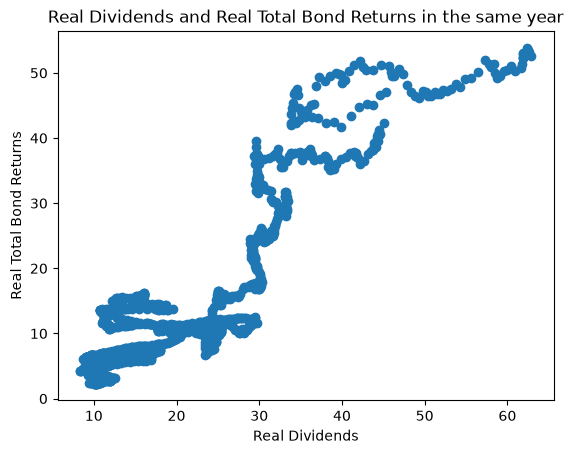

In [38]:
fig, ax = plt.subplots()
ax.scatter(df["Real Dividend"],df["Real Total Bond Returns"])
plt.title("Real Dividends and Real Total Bond Returns in the same year")
plt.xlabel("Real Dividends")
plt.ylabel("Real Total Bond Returns")

s, p= scipy.stats.pearsonr(df["Real Dividend"],df["Real Total Bond Returns"], alternative="two-sided")

print("P Value: ", p)
print("Correlation Statistic: ", s)

In this case, the P value is impressively 0, implying that the null hypothesis is very wrong and that over the course of the data, the dividend and return value are heavily correlated. As the correlation statistic "r" is positive, it implies a positive correlation. When one goes up, the other also goes up. It should be noted that this does not mean that increased dividends result in increased bond returns, or vice versa. Rather there is likely some confounding variable -- such as the economy -- that is affecting both, and this variable may not be properly capture by our datasets. It's hard to gauge the concept of the economy in a simple variable.

It's worth noting that the P value is likely not truly zero, rather, it's just so low that the computer renders it as zero. This is likely due to the high correlation value across a rather large dataset causing the t-test statistic used by the pearsonr function (the t-test statistic is roughly 70.5) and thus results in an absurdly low p value once the t-statistic is analyzed.